In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'marenaria')
pth_feat = os.path.join(pth_data, 'features', 'orthofinder')
pth_out = os.path.join(pth_data, 'results', 'marenaria')
pth_fig = os.path.join(pth, 'figures', 'marenaria')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'MarBTN.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 6 × 43038
    obs: 'sample'
    uns: 'log1p'
    layers: 'counts'

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# gene/module scores
g = feat_dict['union'].marenaria.drop_duplicates()
adata.layers['score'] = adata.X - adata[:, g].X.mean(axis = 1)[:, None]
for src, df_src in feat_dict.items():
    if src != 'union':
        print(src)
        g = df_src.marenaria.drop_duplicates()
        adata.obs[src] = adata[:, g].layers['score'].mean(axis = 1)

GSE162534
GSE229103
rRNAModifications


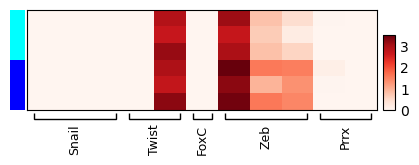

In [8]:
g_plt = {
    'Snail' : ['LOC128242410', 'LOC128243129', 'LOC128243408'],
    'Twist' : ['LOC128243558', 'LOC128244610'],
    'FoxC'  : ['LOC128244946'],
    'Zeb'   : ['LOC128234774', 'LOC128243217', 'LOC128220362'],
    'Prrx'  : ['LOC128227203', 'LOC128226215']}
adata.uns['sample_colors'] = ['blue'] * 3 + ['cyan'] * 3

# expression heatmap
hm = sc.pl.heatmap(adata, g_plt, 'sample',
                   layer = 'score',
                   cmap = 'Reds', vmin = 0,
                   figsize = (5, 1.5),
                   show_gene_labels = False,
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_var = hm['gene_groups_ax']
ax_cb = ax_hm.figure.axes[1]

pos_hm  = ax_hm.get_position()
pos_var = ax_var.get_position()
pos_cb = ax_cb.get_position()

ax_grp.set_yticks([])
ax_grp.set_ylabel('')

for ax in (ax_hm, ax_grp, ax_var):
    ax.invert_yaxis()

for t in ax_var.texts:
    t.set_va('top')
    t.set_fontsize(9)

for l in ax_var.patches:
    l.set_linewidth(1)

ax_var.set_position([pos_var.x0,
                     pos_hm.y0 - pos_var.height - .02,
                     pos_var.width,
                     pos_var.height])

ax_cb.set_position([pos_cb.x0, pos_cb.y0, .025, .5])
ax_cb.set_yticks([0, 1, 2, 3])
ax_cb.tick_params(length = 0)

for l in ax_hm.collections: l.remove()
fn = os.path.join(pth_fig, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 600)

In [ ]:
# sc.pl.heatmap(adata, ['GSE162534', 'GSE229103', 'rRNAModifications'], groupby = 'sample', cmap = 'plasma', vmin = 0)

In [ ]:
# adata.write(os.path.join(pth_in, 'scores.h5ad'))